### Restrictions:
• Maximum 5,000 words in Markdown cells throughout the notebook
<br>• Maximum 100 words per Markdown cell.
<br>• Maximum 30 lines of code per code block, excluding blank lines.
<br>• Maximum 15 figures throughout the notebook.
<br>• Report only the top 5 hyperparameter configuration results for each model.
<br>• Do not include comments within code blocks. Explanations of the code should be
provided in the corresponding Markdown cells instead.

# Description of the dataset

State a brief description of the dataset.
<br>• Provide a description of the collection process executed to build the dataset. Note that
you may need to look at relevant sources related to the dataset to acquire necessary
information for this part of the project.
<br>• Describe the structure of the dataset file.
<br>o What does each row and column represent?
<br>o How many instances are there in the dataset?
<br>o How many features are there in the dataset?
<br>o If the dataset is composed of different files that you will combine in the succeeding
steps, describe the structure and the contents of each file.
<br>• Discuss the features in each dataset file. What does each feature represent? All features,
even those which are not used for the study, should be described to the reader. The
purpose of each feature in the dataset should be clear to the reader of the notebook
without having to go through an external link.

# List of requirements

In [127]:
from encodings import mac_latin2
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
SEED = 55

Import libraries for loading and cleaning data as well as splitting the dataset

# Data Cleaning, Preprocessing and EDA

## Cleaning

In [128]:
raw = pd.read_csv("dataset_Cheat_Detection.csv", sep=";", decimal=",")

Read the file and define that ; is a separator and , is the decimal point because the dataset has European format

In [129]:
cleaned = raw.drop(columns=['timestamp', 'isAimbot_max', 'isVidaInfinita_max', 'isMunicionInfinita_max', 'isSuperVelocidad_max'])

Remove the **Timestamp** Column because nearly every row has a unique value, so it works more as an identifier rather than a feature. The model may end up learning a time-based pattern instead of looking at the other feature values to decide whether cheating occurred or not.

**isAimbot_max, isVidaInfinita_max, isMunicionInfinita_max, and isSuperVelocidad_max** were also removed because they are sub-labels of **es_trampa_max**, which is 1 (Cheating) whenever at least one of them is true. Keeping them would leak the target to the model, and they would not be available in a real-world scenario.

In [130]:
cleaned.isna().sum()

angle_error_mean          0
angle_error_max           0
speed_mean                0
speed_max                 0
is_shot_sum               0
is_hit_sum                0
is_received_damage_sum    0
health_mean               0
ammo_left_min             0
ammo_max                  0
es_trampa_max             0
accuracy_rate             0
infinite_ammo_ratio       0
dtype: int64

Check if there are any cells with missing values that may affect the model's training or lead to errors during preprocessing.

In [131]:
dup_count = cleaned.duplicated().sum()
print ("Duplicates: ", dup_count)
if dup_count > 0:   
    cleaned.drop_duplicates(subset=None, inplace=True)

print(f'Before: {len(raw)} rows')
print(f'Target: {len(cleaned)} rows')

Duplicates:  60
Before: 3584 rows
Target: 3524 rows


Check if there are any duplicated rows that could lead to the model developing a bias and also preventing a leakage. There were 60 duplicates found since we removed the Timestamp column.


In [132]:
features = cleaned.drop(columns = "es_trampa_max")

print("Min:", features.min().min())
print("Max:", features.max().max())
print("All features in [0,1]:", ((features >= 0) & (features <= 1)).all().all(), "\n")

print("Label values:", sorted(cleaned["es_trampa_max"].unique()), "\n")

Min: 0.0
Max: 1.0
All features in [0,1]: True 

Label values: [np.float64(0.0), np.float64(1.0)] 



Checked for misrepresented values. All features fall within [0, 1], showing the data was already scaled by the source, and the label only contains 0 and 1. No invalid values were found.

## Pre-Processing

In [133]:
cleaned["es_trampa_max"] = cleaned["es_trampa_max"].astype(int)
print(cleaned["es_trampa_max"].dtype)

int64


The label es_trampa_max was stored as a decimal (0.0 or 1.0). It was changed to a whole number (0 or 1) because it only marks two groups, Not Cheating (0) and Cheating (1), rather than measuring an amount.

In [134]:
cleaned.to_csv("cleanedDataset.csv", index=False)

Save changes to the cleaned csv file. Below is the list of Pre-Processing techniques that were not applied:

Normalization: all features are already scaled to [0, 1]

One-hot encoding: Features are numeric, with no categorical columns.

Feature engineering: accuracy_rate (hits ÷ shots) and infinite_ammo_ratio (share of records where ammo didn't decrease) were provided by the source, so no new features were created.

Outliers: Extreme values come from Cheaters, removing them would delete the patterns the model needs to learn.

Standardization: Not applied at this stage. It will be fitted on the training set only, after splitting, to prevent data leakage.

## Exploratory Data Analysis

In [135]:
rawAnalysis = raw.describe()
cleanedAnalysis = cleaned.describe()

compare = pd.concat([rawAnalysis, cleanedAnalysis], axis = 1, keys=['Raw Dataset', 'Cleaned Dataset'])
compare = compare.swaplevel(0, 1, axis = 1).sort_index(axis = 1)

label = 'es_trampa_max'
raw_counts = raw[label].value_counts()
cleaned_counts = cleaned[label].value_counts()

raw_pct = raw[label].value_counts(normalize=True) * 100
cleaned_pct = cleaned[label].value_counts(normalize=True) * 100

label_compare = pd.concat([raw_counts, raw_pct, cleaned_counts, cleaned_pct], axis=1, keys=['Raw Count', 'Raw %', 'Cleaned Count', 'Cleaned %'])

rawClassMeans = raw[cleaned.columns].groupby("es_trampa_max").mean(numeric_only=True).T
cleanedClassMeans = cleaned.groupby("es_trampa_max").mean().T

classCompare = pd.concat([rawClassMeans, cleanedClassMeans], axis=1,
                         keys=["Raw Dataset", "Cleaned Dataset"])
print(compare, "\n\n")
print(label_compare, "\n\n")
print(classCompare)

        accuracy_rate                ammo_left_min               \
      Cleaned Dataset  Raw Dataset Cleaned Dataset  Raw Dataset   
count     3524.000000  3584.000000     3524.000000  3584.000000   
mean         0.460943     0.453227        0.360510     0.355521   
std          0.380616     0.382022        0.407238     0.406748   
min          0.000000     0.000000        0.000000     0.000000   
25%          0.000000     0.000000        0.000000     0.000000   
50%          0.454545     0.440972        0.125000     0.125000   
75%          0.818182     0.800000        0.750000     0.750000   
max          1.000000     1.000000        1.000000     1.000000   

             ammo_max              angle_error_max               \
      Cleaned Dataset  Raw Dataset Cleaned Dataset  Raw Dataset   
count     3524.000000  3584.000000     3524.000000  3584.000000   
mean         0.596481     0.587542        0.130310     0.128129   
std          0.403681     0.407235        0.253426     0.2518

### Comparison of Raw and Cleaned Datasets
A summary analysis using describe() was implemented for both the Raw and Cleaned datasets to compare changes. The table confirms that the statistics are nearly unchanged. Every feature's mean shifted less than 0.01, and the standard deviations change by less than 0.004. The medians stayed relatively the same. Therefore, removing the duplicate rows and irrelevant columns did not distort the distribution of the features and the balance between Cheating and Not Cheating

The label **es_trampa_max** values were also counted and showed that the ratio of Cheating and Not Cheating classes were preserved. Cheating went from 48.35% in the Raw Dataset to 48.52% in the Cleaned Dataset. Accuracy would also be a reliable evaluation metric.

### Observations and Challenges

Balanced classes: The split is very close to 50/50, so the model would not require adding or subtracting samples or instances.
<br>Skewed Features: Observing the dataset, many features have a lot of zeros, resulting in a positive skew distribution. For example, **angle_error_mean** has a mean of 0.093, but its median is at 0.007. Most normal players stay near zero, and the higher values mostly come from cheaters.

Gap between Classes: The mean for Cheaters is much higher on multiple features compared to Non-Cheaters. The largest differences are:
       <br>a. **ammo_left_min** (0.517 vs 0.213)\
       b. **infinite_ammo_ratio** (0.275 vs 0.038)\
       c. **angle_error_max** (0.252 vs 0.015)\
    These three feature may be the biggest indicators for Cheating, which suggests the model can perform well

# Dataset Split

In [136]:
x = cleaned.drop(columns = "es_trampa_max")
y = cleaned["es_trampa_max"]

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size = 0.30, random_state = SEED, stratify = y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size = 0.50, random_state = SEED, stratify = y_temp)

x contains all features while y contains **es_trampa_max**. The data was split twice to get 70/15/15. The first split keeps 70% of training and holds the 30% in a temporary set. The second split cuts the temporary set in half to give both the validation set and training set a 15% split. Both split functions use stratify so every set keeps about 48.5% of Cheaters. Both also use **random_state = SEED** so the split comes out the same every time.

In [137]:
splits = {"Train": y_train, "Validation": y_val, "Test": y_test}

summary = pd.DataFrame({
    name: {
        "Rows": len(s),
        "Not Cheating": (s == 0).sum(),
        "Cheating": (s == 1).sum(),
        "% Cheating": round(s.mean() * 100, 2)
    }
    for name, s in splits.items()
}).T

print(summary)

              Rows  Not Cheating  Cheating  % Cheating
Train       2466.0        1269.0    1197.0       48.54
Validation   529.0         273.0     256.0       48.39
Test         529.0         272.0     257.0       48.58


The Cheating share stays between 48.39% and 48.58% in all three sets, close to the 48.52% in the cleaned dataset. This confirms the stratified split kept the classes balanced.

In [138]:
pd.concat([x_train, y_train], axis=1).to_csv("trainSet.csv", index=False)
pd.concat([x_val, y_val], axis=1).to_csv("validationSet.csv", index=False)
pd.concat([x_test, y_test], axis=1).to_csv("testSet.csv", index=False)

Each set is saved as its own CSV so both models are trained and tested on exactly the same rows.

## Data Leakage Prevention

1. The timestamp and the four sub-labels were removed before splitting, so no column gives away the answer.
2. Duplicates were removed before splitting, so the same row cannot be in both the training and test sets.
3. Any scaler will be fitted on the training set only, then applied to validation and test.
4. The validation set is used to tune hyperparameters. The test set is used only once, for the final evaluation.

## Limitation

Each row summarizes only 2 seconds of one player's game, so one play session is split into many back-to-back rows. Rows from the same moment look almost the same because the player's speed, aim, and health would barely change in seconds. A random split can place one of these rows in training and the next in testing, which is a form of data leakage. The model is then tested on rows it has nearly seen before, so the test score may be higher than its true performance on new players and could hide overfitting.

# Model training

## Naive Bayes

The first machine learning model utilized in this project was the Gaussian Naive Bayes model. This model is a supervised machine learning model which uses the Bayes’ Theorem in order to calculate the probability that a particular instance belongs to a certain label.

It has the following assumptions:

1. That all numerical features follow a Gaussian distribution within each label.
2. That there is conditional independence between the features given the target label.

This model was chosen due to the Gaussian Naive Bayes model being specifically designed for numerical features while using Gaussian distributions.

Prediction Test - Training

In [139]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
train_data = pd.read_csv("trainSet.csv")

gnbX_T_Train, gnbY_T_Train = train_data.drop(columns = ["es_trampa_max"]), train_data["es_trampa_max"]

gaussianModel_Train = GaussianNB()
gaussianModel_Train.fit(gnbX_T_Train, gnbY_T_Train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-10
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [140]:
gnbY_T_Prediction = gaussianModel_Train.predict(gnbX_T_Train)
print(classification_report(gnbY_T_Train, gnbY_T_Prediction))

              precision    recall  f1-score   support

           0       0.70      0.98      0.82      1269
           1       0.97      0.55      0.70      1197

    accuracy                           0.77      2466
   macro avg       0.83      0.77      0.76      2466
weighted avg       0.83      0.77      0.76      2466



Prediction Test - Validation

In [141]:
validation_data = pd.read_csv("validationSet.csv")
gnbX_Validate, gnbY_Validate = validation_data.drop(columns = ["es_trampa_max"]), validation_data["es_trampa_max"]


In [142]:
gnbY_V_Prediction = gaussianModel_Train.predict(gnbX_Validate)
print(classification_report(gnbY_Validate, gnbY_V_Prediction))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



Hyperparameter Comparison And Testing

Test 1: var_smoothing value = 1e-9

In [143]:
gaussianModel_paramTesting_1 = GaussianNB(var_smoothing=1e-9)
gaussianModel_paramTesting_1.fit(gnbX_T_Train, gnbY_T_Train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-10
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [144]:
paramTesting_Prediction_1 = gaussianModel_paramTesting_1.predict(gnbX_Validate)
param_probability1 = gaussianModel_paramTesting_1.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_1))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



Test 2: var_smoothing value = 1e-8

In [145]:
gaussianModel_paramTesting_2 = GaussianNB(var_smoothing=1e-8)
gaussianModel_paramTesting_2.fit(gnbX_T_Train, gnbY_T_Train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-08
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [146]:
paramTesting_Prediction_2 = gaussianModel_paramTesting_2.predict(gnbX_Validate)
param_probability2 = gaussianModel_paramTesting_2.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_2))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



Test 3: var_smoothing value = 1e-7

In [147]:
gaussianModel_paramTesting_3 = GaussianNB(var_smoothing=1e-7)
gaussianModel_paramTesting_3.fit(gnbX_T_Train, gnbY_T_Train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-07
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-08
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [148]:
paramTesting_Prediction_3 = gaussianModel_paramTesting_3.predict(gnbX_Validate)
param_probability3 = gaussianModel_paramTesting_3.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_3))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



Test 4: var_smoothing value = 1e-6

In [149]:
gaussianModel_paramTesting_4 = GaussianNB(var_smoothing=1e-6)
gaussianModel_paramTesting_4.fit(gnbX_T_Train, gnbY_T_Train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-06
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [150]:
paramTesting_Prediction_4 = gaussianModel_paramTesting_4.predict(gnbX_Validate)
param_probability4 = gaussianModel_paramTesting_4.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_4))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



Test 5: var_smoothing value = 1e-5

In [151]:
gaussianModel_paramTesting_5 = GaussianNB(var_smoothing=1e-5)
gaussianModel_paramTesting_5.fit(gnbX_T_Train, gnbY_T_Train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-05
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1269.,1197.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.51,0.49]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.648e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['angle_error_mean','angle_error_max','speed_mean',...,'ammo_max', 'accuracy_rate','infinite_ammo_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[0.01,0.02,0.17,...,0.53,0.39,0.04], [0.17,0.25,0.25,...,0.67,0.54,0.28]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0. ,0. ,0.01,...,0.15,0.12,0. ], [0.06,0.1 ,0.03,...,0.16,0.16,0.12]]"


In [152]:
paramTesting_Prediction_5 = gaussianModel_paramTesting_5.predict(gnbX_Validate)
param_probability5 = gaussianModel_paramTesting_5.predict_proba(gnbX_Validate)
print(classification_report(gnbY_Validate, paramTesting_Prediction_5))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529



In [153]:
print(np.allclose(param_probability1, param_probability2))
print(np.allclose(param_probability1, param_probability3))
print(np.allclose(param_probability1, param_probability4))
print(np.allclose(param_probability1, param_probability5))

True
False
False
False


In [154]:
Diff_Array1 = param_probability1 - param_probability2
Diff_Array2 = param_probability1 - param_probability3
Diff_Array3 = param_probability1 - param_probability4
Diff_Array4 = param_probability1 - param_probability5

max_Diff1 = np.max(np.abs(Diff_Array1))
max_Diff2 = np.max(np.abs(Diff_Array2))
max_Diff3 = np.max(np.abs(Diff_Array3))
max_Diff4 = np.max(np.abs(Diff_Array4))

print(max_Diff1)
print(max_Diff2)
print(max_Diff3)
print(max_Diff4)



1.915512591765811e-06
2.1070558104074877e-05
0.00021261294854302282
0.0021272069411529815


Grid Search Test

In [155]:
gaussianModel_Grid = GaussianNB()

varSmooth_grid = { 'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5] }
gaussianGS = GridSearchCV(gaussianModel_Grid, varSmooth_grid, cv=5, scoring='f1_macro')

gaussianGS.fit(gnbX_T_Train, gnbY_T_Train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'var_smoothing': [1e-09, 1e-08, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [156]:
gaussianGS.best_params_

{'var_smoothing': 1e-09}

In [157]:
gaussianGS.best_score_

np.float64(0.7598268098835049)

In [158]:
gaussianGS.cv_results_

{'mean_fit_time': array([0.00191913, 0.00142422, 0.00140052, 0.00147047, 0.00170088]),
 'std_fit_time': array([0.00023455, 0.00012223, 0.00011179, 0.00013424, 0.00028871]),
 'mean_score_time': array([0.00234976, 0.0019587 , 0.00188966, 0.00185838, 0.00213652]),
 'std_score_time': array([5.25069180e-04, 2.65821452e-04, 9.23163881e-05, 1.65509731e-04,
        2.45683950e-04]),
 'param_var_smoothing': masked_array(data=[1e-09, 1e-08, 1e-07, 1e-06, 1e-05],
              mask=[False, False, False, False, False],
        fill_value=1e+20),
 'params': [{'var_smoothing': 1e-09},
  {'var_smoothing': 1e-08},
  {'var_smoothing': 1e-07},
  {'var_smoothing': 1e-06},
  {'var_smoothing': 1e-05}],
 'split0_test_score': array([0.75766127, 0.75766127, 0.75766127, 0.75766127, 0.75766127]),
 'split1_test_score': array([0.7836603, 0.7836603, 0.7836603, 0.7836603, 0.7836603]),
 'split2_test_score': array([0.75496163, 0.75496163, 0.75496163, 0.75496163, 0.75496163]),
 'split3_test_score': array([0.73929138, 

In [159]:
best_GaussianGS = gaussianGS.best_estimator_

best_Predictions = best_GaussianGS.predict(gnbX_Validate)

print(classification_report(gnbY_Validate, best_Predictions))
print(confusion_matrix(gnbY_Validate, best_Predictions))
print(accuracy_score(gnbY_Validate, best_Predictions))

              precision    recall  f1-score   support

           0       0.74      0.99      0.85       273
           1       0.98      0.63      0.77       256

    accuracy                           0.81       529
   macro avg       0.86      0.81      0.81       529
weighted avg       0.85      0.81      0.81       529

[[269   4]
 [ 94 162]]
0.8147448015122873


Prediction Test - testSet

In [160]:
test_data = pd.read_csv("testSet.csv")
gnbX_actualTest = test_data.drop(columns = ["es_trampa_max"])
gnbY_actualTest = test_data["es_trampa_max"]

actualTest_Predictions = best_GaussianGS.predict(gnbX_actualTest)

print(classification_report(gnbY_actualTest, actualTest_Predictions))
print(confusion_matrix(gnbY_actualTest, actualTest_Predictions))
print(accuracy_score(gnbY_actualTest, actualTest_Predictions))

              precision    recall  f1-score   support

           0       0.71      0.99      0.83       272
           1       0.98      0.58      0.73       257

    accuracy                           0.79       529
   macro avg       0.85      0.78      0.78       529
weighted avg       0.84      0.79      0.78       529

[[269   3]
 [108 149]]
0.7901701323251418


## Decision Trees

As the data is suprvised, there exists labels, the model should be able to learn yes/no questions from the trainSet.csv and use it to analyze the values present in the other sets.

### Load the Splits

In [161]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

train = pd.read_csv("trainSet.csv")
val = pd.read_csv("validationSet.csv")
test = pd.read_csv("testSet.csv")

x_train, y_train = train.drop(columns = ["es_trampa_max"]), train["es_trampa_max"]
x_val, y_val = val.drop(columns = ["es_trampa_max"]), val["es_trampa_max"]
x_test, y_test = test.drop(columns = ["es_trampa_max"]), test["es_trampa_max"]

print("Train shape:", x_train.shape, y_train.shape)
print("Validation shape:", x_val.shape, y_val.shape)
print("Test shape:", x_test.shape, y_test.shape)

Train shape: (2466, 12) (2466,)
Validation shape: (529, 12) (529,)
Test shape: (529, 12) (529,)


### Gini Index

In order to find the best 'yes/no' question for the root node, we must calculate the gini index and choose the lowest score. If there is a high train score but the validation score is low, or a deep tree, or too many leaves, then it is counted as overfitting

In [162]:
def evaluate(model, x, y):
    pred = model.predict(x)
    return{
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1 Score": f1_score(y, pred),
    }

baseline = DecisionTreeClassifier(criterion="gini", random_state=SEED)
baseline.fit(x_train, y_train)

baseline_results = pd.DataFrame({
    "Train": evaluate(baseline, x_train, y_train),
    "Validation": evaluate(baseline, x_val, y_val),
    "Test": evaluate(baseline, x_test, y_test)
}).T

print(baseline_results)
print("Depth: ", baseline.get_depth(), " | Leaves: ", baseline.get_n_leaves())

            Accuracy  Precision    Recall  F1 Score
Train       0.999594   1.000000  0.999165  0.999582
Validation  0.901701   0.898438  0.898438  0.898438
Test        0.871456   0.873518  0.859922  0.866667
Depth:  22  | Leaves:  251


### Hyperparameter Tuning

Every combination of criterion, max_depth, and min_samples_leaf is trained on the training set and scored on the validation set. These settings act as the threshold which limit tree depth and the number of samples per leaf.

In [163]:
rows = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 4, 5, 6, 7, 8, 9, 10, None]:
        for leaf in [1, 5, 10, 20]:
                model = DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=depth,
                    min_samples_leaf=leaf,
                    random_state=SEED
                )
                model.fit(x_train, y_train)
                rows.append({
                    "Criterion": criterion,
                    "Max Depth": str(depth),
                    "Min Samples Leaf": leaf,
                    "Leaves": model.get_n_leaves(),
                    "Train F1": f1_score(y_train, model.predict(x_train)),
                    "Validation F1": f1_score(y_val, model.predict(x_val)),
                    "Model": model,
                })

tuning = pd.DataFrame(rows).sort_values(["Validation F1", "Leaves"], ascending=[False, True])
print(tuning.drop(columns=["Model"]).head(10).round(4).to_string(index=False))

Criterion Max Depth  Min Samples Leaf  Leaves  Train F1  Validation F1
     gini        10                 1     112    0.9493         0.9044
     gini         8                 1      68    0.9199         0.9027
     gini         8                10      47    0.9051         0.9008
  entropy         8                 5      60    0.9111         0.9004
     gini         7                10      36    0.9047         0.9002
  entropy         9                 5      72    0.9202         0.8994
     gini      None                 1     251    0.9996         0.8984
  entropy         7                 5      42    0.9038         0.8975
     gini         9                 1      88    0.9320         0.8975
  entropy         8                20      38    0.8923         0.8967


Rows are ranked by validation F1 and ties go to the tree with fewer leves because a simpler tree is better for generalization.

### Best Model

The top-ranked setting is chosen as the final model. The table compares it with the baseline tree on the validation set.

In [164]:
best = tuning.iloc[0]

best_model = best["Model"]

print("Criterion:", best["Criterion"], "| Max Depth:", best["Max Depth"], "| Min Samples Leaf:", best["Min Samples Leaf"], "| Leaves:", best["Leaves"])

comparison = pd.DataFrame({
    "Baseline": evaluate(baseline, x_val, y_val),
    "Trained": evaluate(best_model, x_train, y_train),
    "Validation (Tuned)": evaluate(best_model, x_val, y_val)
}).T

print(comparison.round(4).to_string())

Criterion: gini | Max Depth: 10 | Min Samples Leaf: 1 | Leaves: 112
                    Accuracy  Precision  Recall  F1 Score
Baseline              0.9017     0.8984  0.8984    0.8984
Trained               0.9521     0.9779  0.9223    0.9493
Validation (Tuned)    0.9093     0.9228  0.8867    0.9044


If the gap between the Train and Validation is smaller than the baseline's gap, tuning reduced overfitting. Also, if the validation scores are close to the training scores, then that means that the tree generalizes well.

## Final Test Evaluation

The test set is used at the very end, when all tuning is finished in order to give us an unbiased estimate.

Accuracy     0.8885
Precision    0.9091
Recall       0.8560
F1 Score     0.8818


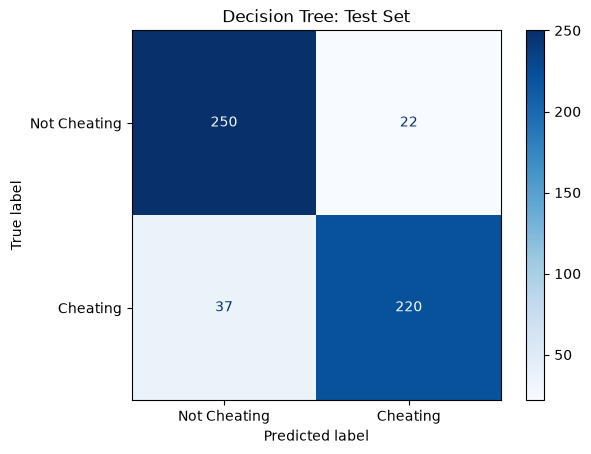

In [165]:
test_pred = best_model.predict(x_test)

print(pd.Series(evaluate(best_model, x_test, y_test)).round(4).to_string())

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not Cheating", "Cheating"]).plot(cmap="Blues")
plt.title("Decision Tree: Test Set")
plt.show()

In the confusion matrix, rows represent the actual classes while columns represent the predictions.

The top-right cell are false positives while the bottom-left cells are false negatives.

## Visualizing The Tree

Each box shows the yes/no question, the Gini value, the number of samples, and the class counts.

The left branch are the 'yes'-es and the right branch are the 'no'-s.

The color shows the majority class and gets darker as the box becomes purer

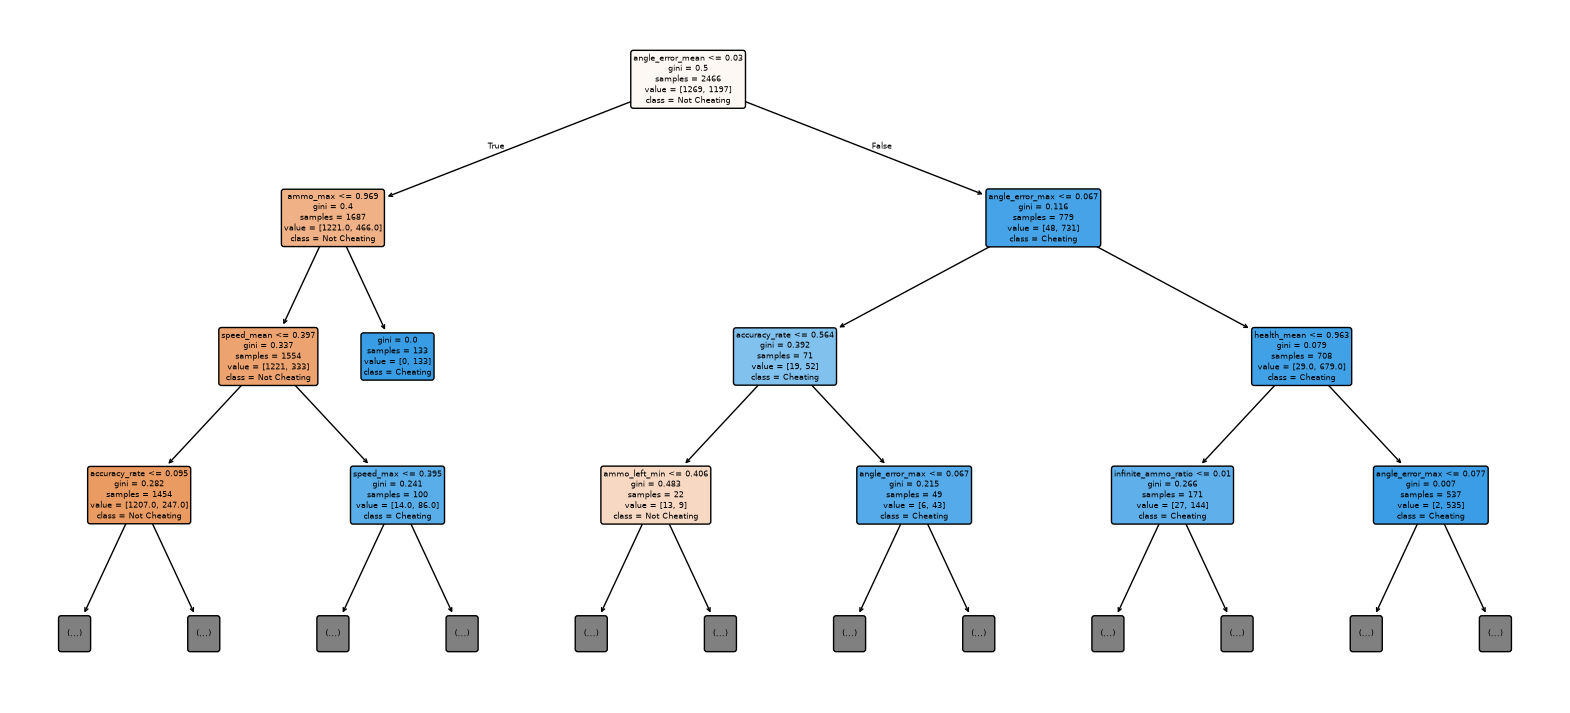

In [166]:
plt.figure(figsize=(20, 9))

plot_tree(best_model, feature_names=x_train.columns, class_names=["Not Cheating", "Cheating"], filled=True, rounded=True, max_depth=3)

plt.show()

Only the top 3 levels are drawn so that the tree is easily digestable.

## Feature Importance

Feature importancce adds up how much each feature lowered the Gini impurity across all of its splits, normalized to 1.

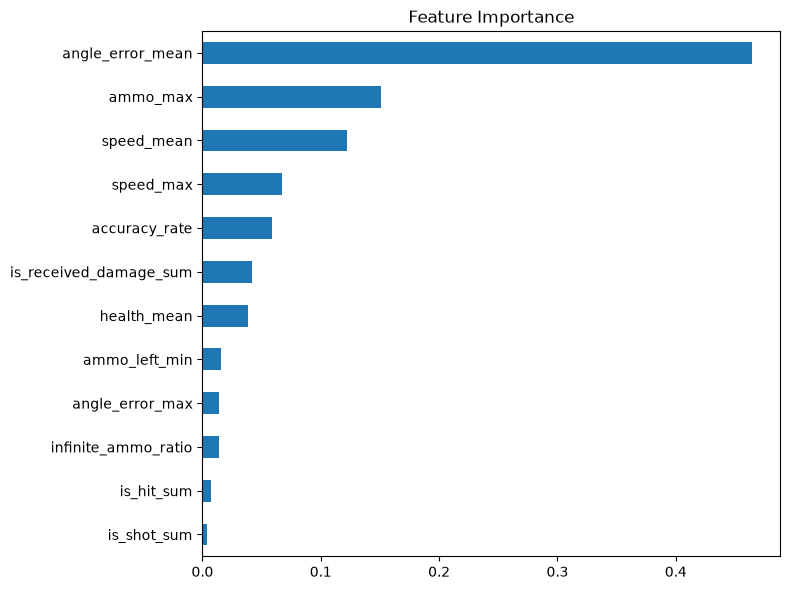

angle_error_mean          0.4648
ammo_max                  0.1508
speed_mean                0.1225
speed_max                 0.0676
accuracy_rate             0.0591
is_received_damage_sum    0.0420
health_mean               0.0385
ammo_left_min             0.0156
angle_error_max           0.0141
infinite_ammo_ratio       0.0136
is_hit_sum                0.0071
is_shot_sum               0.0043


In [167]:
importance = pd.Series(best_model.feature_importances_, index=x_train.columns)

importance = importance.sort_values()

importance.plot(kind="barh", figsize=(8, 6), title="Feature Importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(4).to_string())

The top features are the ones which the tree relies on the most. These can be compared with the EDA, where certain groups showed the largest gaps between cheateres and non-cheaters.

## Error Analysis

### Gaussian Naive Bayes model
achieved an accuracy of 86%. With an overall good performance but some classification errors. Correctly identifying all non-cheaters. But with 79% precision, this indicates that some cheater samples were incorrectly classified as non-cheaters. the cheaters label, the model achieved perfect precision, but has a lower recall of 67%, meaning it failed to detect actual cheaters.

In [168]:
cm = confusion_matrix(gnbY_actualTest, actualTest_Predictions)

cm_df = pd.DataFrame(cm, index = ["Actual 0", "Actual 1"], columns = ["Predicted 0", "Predicted 1"])

print(cm_df)

          Predicted 0  Predicted 1
Actual 0          269            3
Actual 1          108          149


The confusion matrix shows that the Gaussian Naive Bayes model correctly classified 269 non-cheaters and 146 cheaters. While misclassifying 111 cheaters as non cheaters and 3 non-cheaters as cheaters. Indicating that the model is highly effective at avoiding false accusations but is less successful at detecting cheating instances.